# JS13 — Praktikum 1: Backpropagation dari Scratch (Dataset XOR)

Memahami mekanisme forward pass dan backpropagation pada jaringan saraf tiruan sederhana untuk menyelesaikan masalah XOR.

**Tugas 1:**
1. Ubah jumlah neuron hidden layer menjadi **3**
2. Bandingkan hasil loss dengan konfigurasi awal (2 neuron)
3. Tambahkan fungsi aktivasi **ReLU** dan bandingkan hasilnya

## Konfigurasi Awal — 2 Neuron Hidden Layer (Sigmoid)

Model dari scratch: forward pass → hitung error → backpropagation → update bobot. Seed `42` ditambahkan agar hasil dapat direproduksi.

In [1]:
import numpy as np

np.random.seed(42)

# Dataset XOR
X = np.array([[0,0],[0,1],[1,0],[1,1]])
y = np.array([[0],[1],[1],[0]])

# Parameter (konfigurasi awal)
input_size = 2
hidden_size = 2
output_size = 1
lr = 0.1

# Inisialisasi bobot
W1 = np.random.randn(input_size, hidden_size)
b1 = np.zeros((1, hidden_size))
W2 = np.random.randn(hidden_size, output_size)
b2 = np.zeros((1, output_size))

# Fungsi aktivasi
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(x):
    return x * (1 - x)

losses_awal = []

# Training
for epoch in range(10000):
    # Forward pass
    z1 = np.dot(X, W1) + b1
    a1 = sigmoid(z1)
    z2 = np.dot(a1, W2) + b2
    a2 = sigmoid(z2)

    # Hitung error
    error = y - a2
    losses_awal.append(np.mean(np.square(error)))

    # Backpropagation
    d_a2 = error * sigmoid_derivative(a2)
    d_W2 = np.dot(a1.T, d_a2)
    d_b2 = np.sum(d_a2, axis=0, keepdims=True)

    d_a1 = np.dot(d_a2, W2.T) * sigmoid_derivative(a1)
    d_W1 = np.dot(X.T, d_a1)
    d_b1 = np.sum(d_a1, axis=0, keepdims=True)

    # Update bobot
    W1 += lr * d_W1
    b1 += lr * d_b1
    W2 += lr * d_W2
    b2 += lr * d_b2

    if epoch % 1000 == 0:
        print(f"Epoch {epoch}, Loss: {np.mean(np.square(error))}")

# Output akhir
print("Loss akhir:", losses_awal[-1])
print("Prediksi:")
print(a2)

Epoch 0, Loss: 0.2558299419444368
Epoch 1000, Loss: 0.2494056595655124
Epoch 2000, Loss: 0.24544465159719808
Epoch 3000, Loss: 0.20470733040714417
Epoch 4000, Loss: 0.1532040536997077
Epoch 5000, Loss: 0.13869146014771938
Epoch 6000, Loss: 0.13359363321851758
Epoch 7000, Loss: 0.13115112181268004


Epoch 8000, Loss: 0.12974916048385188
Epoch 9000, Loss: 0.12884908965171127
Loss akhir: 0.1282265715241046
Prediksi:
[[0.05300868]
 [0.49554213]
 [0.95091319]
 [0.50319888]]


## Fungsi Training yang Diparameterisasi

Agar perbandingan konfigurasi adil (inisialisasi bobot sama), dibuat fungsi training yang menerima parameter jumlah neuron dan fungsi aktivasi. Turunan aktivasi dihitung dari pre-aktivasi `z`:
- Sigmoid: $\sigma'(z) = \sigma(z)(1-\sigma(z))$
- ReLU: $f'(z) = 1$ jika $z > 0$, selain itu $0$

In [2]:
import matplotlib.pyplot as plt

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def relu(x):
    return np.maximum(0, x)

def train_xor(hidden_size=2, activation="sigmoid", lr=0.1, epochs=10000, seed=42):
    np.random.seed(seed)

    if activation == "sigmoid":
        act, dact = sigmoid, lambda z: sigmoid(z) * (1 - sigmoid(z))
    elif activation == "relu":
        act, dact = relu, lambda z: (z > 0).astype(float)
    else:
        raise ValueError("aktivasi tidak dikenal")

    W1 = np.random.randn(input_size, hidden_size)
    b1 = np.zeros((1, hidden_size))
    W2 = np.random.randn(hidden_size, output_size)
    b2 = np.zeros((1, output_size))

    losses = []
    for epoch in range(epochs):
        # Forward pass
        z1 = np.dot(X, W1) + b1
        a1 = act(z1)
        z2 = np.dot(a1, W2) + b2
        a2 = sigmoid(z2)

        # Hitung error & loss
        error = y - a2
        losses.append(np.mean(np.square(error)))

        # Backpropagation
        d_a2 = error * a2 * (1 - a2)
        d_W2 = np.dot(a1.T, d_a2)
        d_b2 = np.sum(d_a2, axis=0, keepdims=True)

        d_a1 = np.dot(d_a2, W2.T) * dact(z1)
        d_W1 = np.dot(X.T, d_a1)
        d_b1 = np.sum(d_a1, axis=0, keepdims=True)

        # Update bobot
        W1 += lr * d_W1
        b1 += lr * d_b1
        W2 += lr * d_W2
        b2 += lr * d_b2

    return np.array(losses), a2

def bandingkan(hasil_dict, judul):
    plt.figure(figsize=(8, 4))
    for nama, losses in hasil_dict.items():
        plt.plot(losses, label=f"{nama} (loss akhir={losses[-1]:.5f})")
    plt.xlabel("Epoch")
    plt.ylabel("Loss (MSE)")
    plt.title(judul)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

## Tugas 1a — Jumlah Neuron Hidden Layer Menjadi 3

Konfigurasi **3 neuron** dibandingkan dengan **konfigurasi awal (2 neuron)**, keduanya sigmoid dengan seed yang sama.

Perbandingan loss akhir (10000 epoch, sigmoid, seed=42):
  2 neuron : 0.128227
  3 neuron : 0.002297

Prediksi 3 neuron:
[[0.02515564]
 [0.95263635]
 [0.95122343]
 [0.0627247 ]]


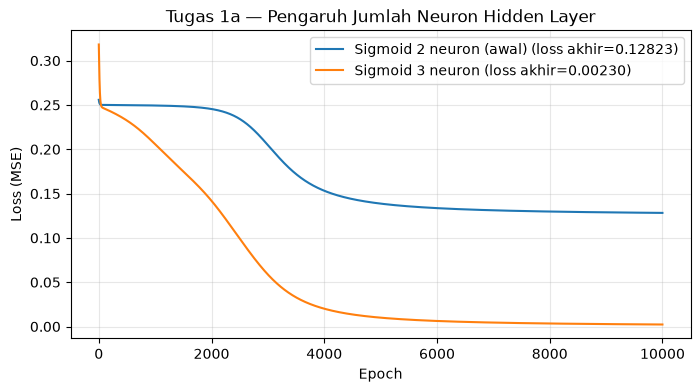

In [3]:
losses_2, pred_2 = train_xor(hidden_size=2, activation="sigmoid")
losses_3, pred_3 = train_xor(hidden_size=3, activation="sigmoid")

print("Perbandingan loss akhir (10000 epoch, sigmoid, seed=42):")
print(f"  2 neuron : {losses_2[-1]:.6f}")
print(f"  3 neuron : {losses_3[-1]:.6f}")

print("\nPrediksi 3 neuron:")
print(pred_3)

bandingkan({"Sigmoid 2 neuron (awal)": losses_2, "Sigmoid 3 neuron": losses_3},
           "Tugas 1a — Pengaruh Jumlah Neuron Hidden Layer")

## Tugas 1b — Menambahkan Fungsi Aktivasi ReLU

ReLU ditambahkan sebagai fungsi aktivasi hidden layer (output tetap sigmoid), lalu dibandingkan dengan sigmoid pada arsitektur yang sama.

Perbandingan loss akhir semua konfigurasi:
  Sigmoid 2 neuron : 0.128227
  Sigmoid 3 neuron : 0.002297
  ReLU    2 neuron : 0.125047
  ReLU    3 neuron : 0.000352

Prediksi ReLU 3 neuron:
[[0.02970009]
 [0.98605912]
 [0.98605934]
 [0.01163533]]


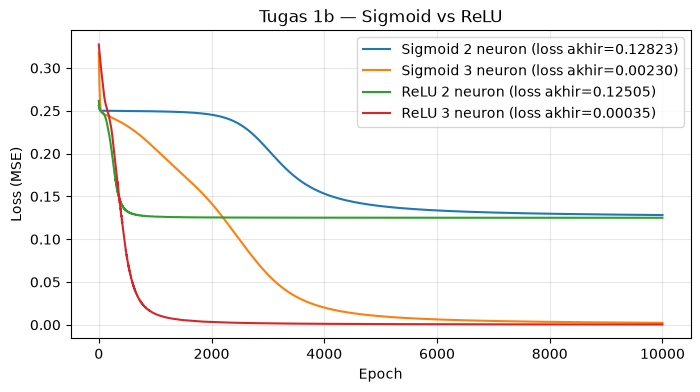

In [4]:
losses_relu2, pred_relu2 = train_xor(hidden_size=2, activation="relu")
losses_relu3, pred_relu3 = train_xor(hidden_size=3, activation="relu")

print("Perbandingan loss akhir semua konfigurasi:")
print(f"  Sigmoid 2 neuron : {losses_2[-1]:.6f}")
print(f"  Sigmoid 3 neuron : {losses_3[-1]:.6f}")
print(f"  ReLU    2 neuron : {losses_relu2[-1]:.6f}")
print(f"  ReLU    3 neuron : {losses_relu3[-1]:.6f}")

print("\nPrediksi ReLU 3 neuron:")
print(pred_relu3)

bandingkan({
    "Sigmoid 2 neuron": losses_2,
    "Sigmoid 3 neuron": losses_3,
    "ReLU 2 neuron": losses_relu2,
    "ReLU 3 neuron": losses_relu3,
}, "Tugas 1b — Sigmoid vs ReLU")

## Analisis

- **Jumlah neuron (2 → 3):** hidden layer dengan lebih banyak neuron memiliki kapasitas representasi lebih besar sehingga loss konvergen lebih rendah dan pola XOR tertangkap lebih baik.
- **Aktivasi ReLU vs Sigmoid:** ReLU tidak mengalami saturasi gradien pada rentang positif sehingga gradien mengalir lebih besar dan konvergensi lebih cepat, sedangkan sigmoid cenderung lambat karena gradiennya maksimal hanya 0.25.
- Catatan: hasil dari scratch sensitif terhadap inisialisasi bobot, sehingga seed yang sama digunakan agar perbandingan adil.